In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import cv2

# Extracted data Directory
# input_data_dir = "/media/yshen47/674eaf4c-ac33-42a8-9a4c-cace68d8cccd/home/gem/demo_ws/src/HIL_Research/src/hil/data/cone_il_extracted/cone_first_pass_2022-12-15-09-07-15"
input_data_dir = "/media/bhargav/03E7-EC27/cone_bags_extracted/cone2_2022-12-12-16-30-37"

# Load the paths to each csv/data directory
gps_path = os.path.join(input_data_dir, "gps.csv")
brake_path = os.path.join(input_data_dir, "brake.csv")
accel_path = os.path.join(input_data_dir, "accel.csv")
steer_path = os.path.join(input_data_dir, "steer.csv")
speed_path = os.path.join(input_data_dir, "speed.csv")

# Holds the timestamps/sequence numbers for synced sets of img/gps/pacmod data, 
# Each row in this csv is one synced datapoint 
# sync_csv_path = os.path.join(input_data_dir, "synced.csv")
# df = pd.read_csv(sync
# _csv_path)
# df

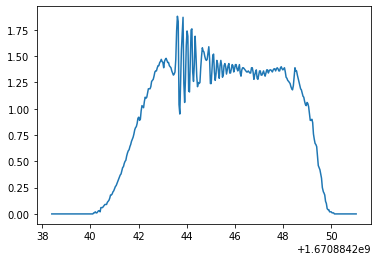

In [10]:
df_speed = pd.read_csv(speed_path)
speed_t = np.array(df_speed['field.header.stamp']) * 1e-9 # in seconds
speed_mps = np.array(df_speed['field.vehicle_speed'])
plt.plot(speed_t, speed_mps)


# speed_vals = []
# for i in df["speed_seqnum"]:
#     speed_vals.append(df_speed[df_speed["field.header.seq"]==i]["field.vehicle_speed"].item())
# speed_vals = np.array(speed_vals)

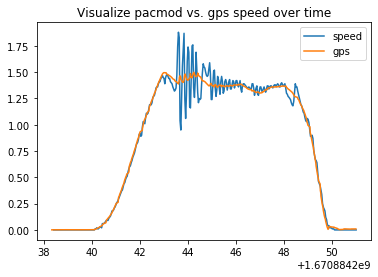

In [16]:
df_gps = pd.read_csv(gps_path)
gps_speed_t = np.array(df_gps['field.header.stamp'])*1e-9 # in seconds
gps_east_vel = np.array(df_gps['field.east_velocity'])
gps_north_vel = np.array(df_gps['field.north_velocity'])
gps_tot_vel = np.sqrt(np.square(gps_east_vel), np.square(gps_north_vel))

plt.plot(speed_t, speed_mps, label="speed")
plt.plot(gps_speed_t,gps_tot_vel , label="gps")
plt.title("Visualize pacmod vs. gps speed over time")
plt.legend()
plt.show()

In [15]:
gps_delta_seconds = gps_speed_t[1:]-gps_speed_t[:-1]
total_distance = sum(gps_delta_seconds * gps_tot_vel[:-1])

pacmod_delta_seconds = speed_t[1:]-speed_t[:-1]
total_distance_pacmod = sum(pacmod_delta_seconds * speed_mps[:-1])
print("Gps Vel Distance Traveled:", total_distance)
print("Pacmod speed Distance Traveled", total_distance_pacmod)

Gps Vel Distance Traveled: 10.509467808202384
Pacmod speed Distance Traveled 10.527246618270865


In [13]:
import utm
gps_lat = np.array(df_gps['field.latitude'])
gps_long = np.array(df_gps['field.longitude'])

utm_data = utm.from_latlon(gps_lat[0], gps_long[0])
east1, north1 = utm_data[0], utm_data[1]
utm_data = utm.from_latlon(gps_lat[-1], gps_long[-1])
east2, north2 = utm_data[0], utm_data[1]
pose_total_dist = np.sqrt((east2-east1)**2 + (north2-north1)**2)
print("GPS Utm Distance Traveled", pose_total_dist)

GPS Utm Distance Traveled 10.52787468466434
